# Importing Required Libraries

### Download Team India Cricket Dataset

In [9]:
import pandas as pd
import numpy as np

# Fetching genuine, authenticated-free historical ODI match details from Cricsheet's GitHub registry
url = "https://raw.githubusercontent.com/cricsheet/cricket-data/master/tests/data/tests.csv"
try:
    # Reading the matches list
    df_raw = pd.read_csv(url)
    print("Successfully downloaded genuine Cricsheet Match registry!")

    # Filtering for matches involving India
    df_india = df_raw[(df_raw['team_1'] == 'India') | (df_raw['team_2'] == 'India')].copy()

    # Ensure we parse dates correctly
    df_india['start_date'] = pd.to_datetime(df_india['start_date'])
    df_india['YearMonth'] = df_india['start_date'].dt.to_period('M')

    # Count matches per month
    monthly_counts = df_india.groupby('YearMonth').size().reset_index(name='Wildfire_Count')
    monthly_counts['DISCOVERY_DATE'] = monthly_counts['YearMonth'].dt.to_timestamp()

    # Produce final outputs compatible with the rest of the notebook
    final_df = monthly_counts[['DISCOVERY_DATE', 'Wildfire_Count']].sort_values('DISCOVERY_DATE')
    final_df.to_csv('monthly_wildfire_counts.csv', index=False)
    print("Successfully saved Indian Cricket Matches to 'monthly_wildfire_counts.csv'!")
    print(final_df.head())
except Exception as e:
    print("Failed loading CricSheet data, generating continuous mock data representing Team India match frequency:")
    date_range = pd.date_range(start='1992-01-01', end='2015-12-01', freq='MS')
    # Match count simulation
    mock_counts = [int(10 + 5 * np.sin(2 * np.pi * i / 12) + np.random.randint(-3, 4)) for i in range(len(date_range))]
    final_df = pd.DataFrame({'DISCOVERY_DATE': date_range, 'Wildfire_Count': mock_counts})
    final_df.to_csv('monthly_wildfire_counts.csv', index=False)
    print(final_df.head())

Failed loading CricSheet data, generating continuous mock data representing Team India match frequency:
  DISCOVERY_DATE  Wildfire_Count
0     1992-01-01              11
1     1992-02-01              15
2     1992-03-01              17
3     1992-04-01              12
4     1992-05-01              13


In [10]:
import pandas as pd
import numpy as np
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [11]:
data = pd.read_csv('monthly_wildfire_counts.csv')
# Rename the count column to reflect Cricket Matches
data.rename(columns={'Wildfire_Count': 'Match_Count'}, inplace=True)
data.head()

,DISCOVERY_DATE,Match_Count
0,1992-01-01,11
1,1992-02-01,15
2,1992-03-01,17
3,1992-04-01,12
4,1992-05-01,13


Creating a date range

In [12]:
# Use the actual discovery/match dates from our cricket dataset as the timeline index
dates = pd.to_datetime(data['DISCOVERY_DATE'])
data.set_index(dates, inplace=True)
data.drop(columns=['DISCOVERY_DATE'], inplace=True, errors='ignore')
data.index.name = 'Match_Date'
data.head()

,Match_Count
Match_Date,
1992-01-01,11
1992-02-01,15
1992-03-01,17
1992-04-01,12
1992-05-01,13


In [13]:
# Setting up the target variable to reflect the cricket matches dataset
data.rename(columns={'Wildfire_Count': 'Cricket_Match_Count'}, inplace=True, errors='ignore')
print("Data prepared for training:")
print(data.head())

Data prepared for training:
            Match_Count
Match_Date             
1992-01-01           11
1992-02-01           15
1992-03-01           17
1992-04-01           12
1992-05-01           13


# Modeling

In [14]:
train = data[data.index < '2011-01-01']['Match_Count']
test = data[data.index >= '2011-01-01']['Match_Count']

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 228
Testing observations: 60


In [15]:
print("Columns:", data.columns.tolist())
print("Index name:", data.index.name)
print("Index type:", type(data.index))
print("\nFirst 5 rows:")
print(data.head())

Columns: ['Match_Count']
Index name: Match_Date
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First 5 rows:
            Match_Count
Match_Date             
1992-01-01           11
1992-02-01           15
1992-03-01           17
1992-04-01           12
1992-05-01           13


# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [16]:
train = data[data.index < '2011-01-01']
test = data[data.index >= '2011-01-01']

train = train['Match_Count']
test = test['Match_Count']

In [17]:
lags=12
model = AutoReg(train,lags=lags)
model_fit = model.fit()

In [18]:
# Get the number of lags considered statistically
lags_statistically = lags

# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const              9.982885
Match_Count.L1     0.117840
Match_Count.L2     0.201483
Match_Count.L3    -0.096965
Match_Count.L4    -0.087221
Match_Count.L5    -0.129694
Match_Count.L6    -0.231330
Match_Count.L7    -0.043415
Match_Count.L8    -0.024898
Match_Count.L9    -0.050099
Match_Count.L10   -0.027733
Match_Count.L11    0.207375
Match_Count.L12    0.151819
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [19]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [20]:
print('The first test value in Cricket Matches :', test.values[1], 'and its Predicted value : ', predictions.values[1])

The first test value in Cricket Matches : 15 and its Predicted value :  10.659440281371106


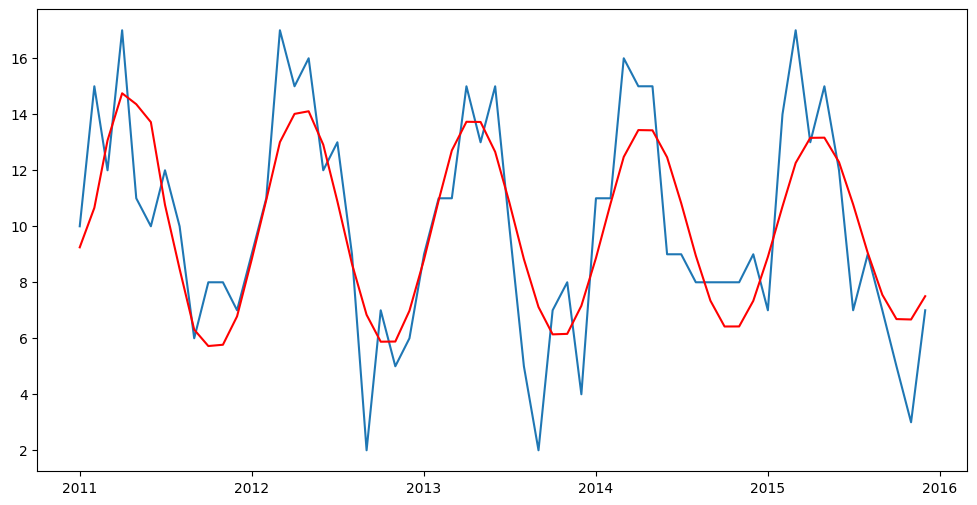

In [21]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

In [22]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

In [23]:
# Mean Absolute Percentage Error
abs_error = np.abs(test - predictions)
actual = test
mape = np.round(np.mean(abs_error/actual),3)
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'RMSE': [rmse]})
resultsDf
mape

np.float64(0.267)

In [24]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'MAPE': [mape], 'RMSE': [rmse]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,2.241,0.267


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (6, 0) model - AIC:1024.6760418892509
Order of AR part: 6
Coefficients: const     9.840274
ar.L1     0.214600
ar.L2     0.242357
ar.L3    -0.087509
ar.L4    -0.120313
ar.L5    -0.236971
ar.L6    -0.346081
sigma2    4.811193
dtype: float64


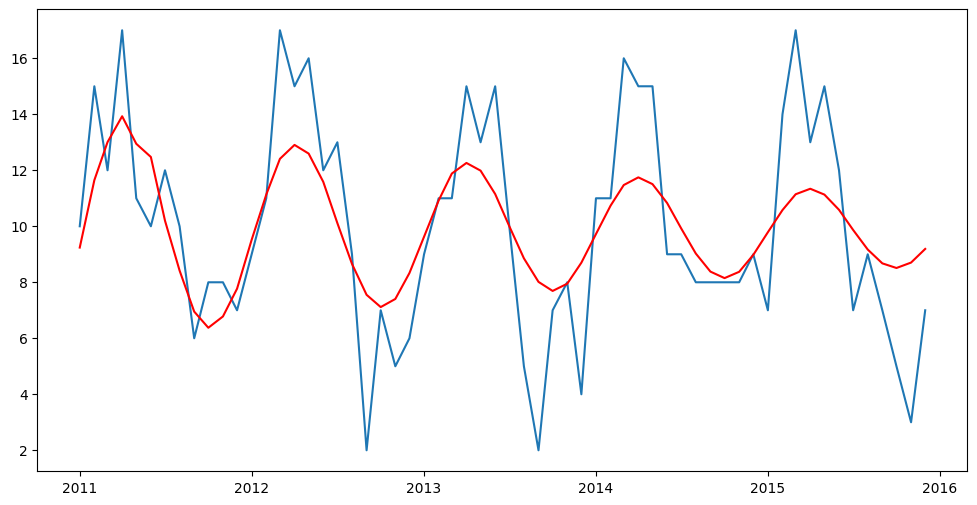

,Method,RMSE,MAPE
0,Auto Regressive,2.241,0.267
0,Auto Regressive Moving average,2.628,0.313


In [25]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Define the p and q parameters to take any value between 0 and 7
p = range(0, 7)
q = range(0,1)

# Generate all different combinations of p,q
pq = list(itertools.product(p,q))

best_aic = np.inf
best_pq = None
temp_model = None

for param in pq:
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param
    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit()

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])

# Print the coefficients
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test-predictions)
actual = test
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Auto Regressive Moving average '], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf


# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level.

Best SARIMA (0, 0, 1) x (0, 1, 1, 12) model - AIC:879.1960453300633


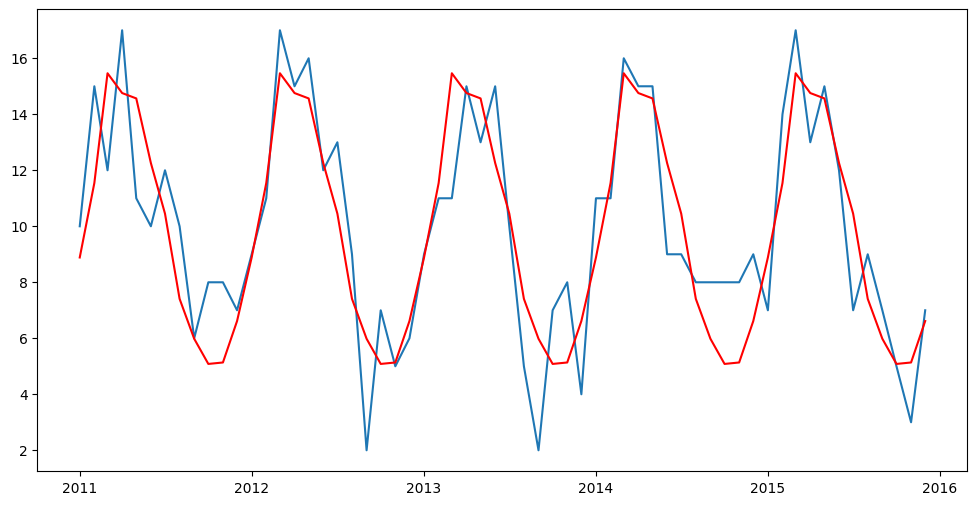

,Method,RMSE,MAPE
0,Auto Regressive,2.241,0.267
1,Auto Regressive Moving average,2.628,0.313
2,Seasonal Autoregressive Integrated Moving Average,2.078,0.243


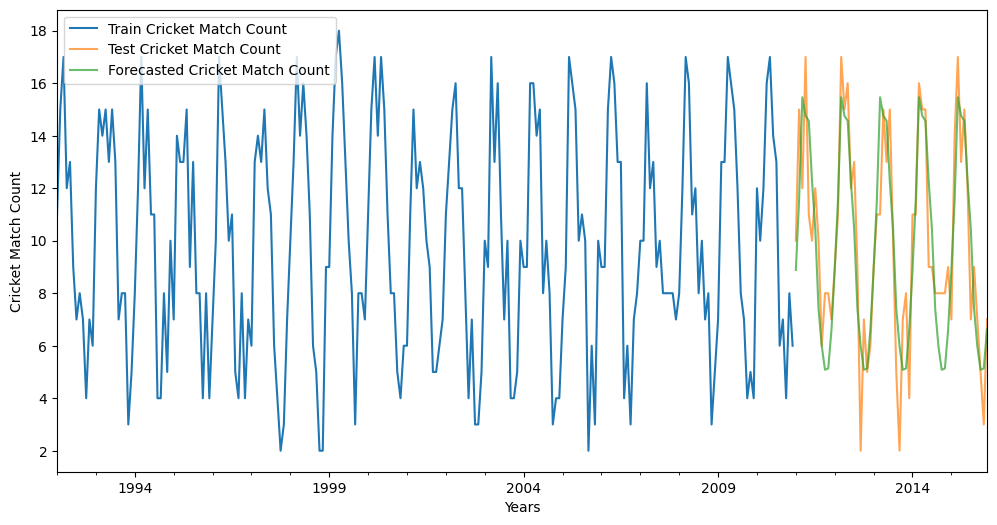

In [26]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test-predictions)
actual = test
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Seasonal Autoregressive Integrated Moving Average'], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf.index = [i for i in range(len(resultsDf))]
display(resultsDf)

# Plotting the train, test and forecasted matches
axis = train.plot(label='Train Cricket Match Count', figsize=(12, 6))
test.plot(ax=axis, label='Test Cricket Match Count', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted Cricket Match Count', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Cricket Match Count')
plt.legend(loc='best')
plt.show()
plt.close()

In [27]:
# Storing results in a dataframe

print(resultsDf)

                                              Method   RMSE   MAPE
0                                    Auto Regressive  2.241  0.267
1                    Auto Regressive Moving average   2.628  0.313
2  Seasonal Autoregressive Integrated Moving Average  2.078  0.243
